In [3]:
import random
import pulp
import numpy as np
from sklearn.cluster import KMeans


# Explication Rapide

## Clients

Le dictionnaire `clients` associe des positions `(i, j)` sur un tableau de taille `(n²) * (n²)` comme clés, à une **liste de clients**. En effet, plusieurs clients peuvent se situer à la même position, conformément aux spécifications de l'énoncé.  
Les positions sans clients associés ne sont pas représentées dans ce dictionnaire.

## Distance Matrix

Le dictionnaire `distance_matrix` contient des paires de nœuds `(noeud1, noeud2)` comme clés, avec pour valeur la **distance de Manhattan** entre ces deux nœuds.  
Le **centre de distribution**, situé au centre du tableau, est identifié comme le **nœud 0**.  
Si `noeud1 = (i, j)` et `noeud2 = (i', j')`, alors la distance de Manhattan entre ces deux nœuds est calculée par :  
$$ \text{distance} = |i - i'| + |j - j'| $$  
De plus, la distance entre le centre de distribution (nœud 0) et lui-même est égale à **0**.


In [5]:
# Génère une instance du problème
def generate_problem(num_clients):
    grid_size = num_clients**2
    clients = {}
    clients[((grid_size-1)/2, (grid_size-1)/2)]=[]
    clients[((grid_size-1)/2, (grid_size-1)/2)].append(0)
    for i in range(1,num_clients+1):
        x = random.randint(0, grid_size - 1)
        y = random.randint(0, grid_size - 1)
        if (x, y) not in clients:
            clients[(x, y)] = []
        clients[(x, y)].append(i)
    
    return clients

In [7]:
# Calcule la distance de Manhattan entre deux points
def manhattan_distance(p1, p2):
    """
    Calcule la distance de Manhattan entre deux points (x1, y1) et (x2, y2).
    """
    return abs(p1[0] - p2[0]) + abs(p1[1] - p2[1])

In [9]:

# Calcule la matrice des distances entre tous les clients

def compute_distance_matrix(clients, num_clients, verbose=False):
    grid_size = num_clients**2
    positions = list(clients.keys())
    distance_matrix = {}
    distance_matrix[(0,0)] = 0  # Ajouter le centre de distribution
    for i in range(len(positions)):
        for j in range(i + 1, len(positions)):
            if verbose:
                print("compute matrix distance ", positions[i], positions[j])
            distance = manhattan_distance(positions[i], positions[j])
            distance_matrix[(i, j)] = distance
            distance_matrix[(j, i)] = distance
    
    return positions, distance_matrix


In [11]:
# Vérifie si une solution est valide
def is_valid_solution(solution, num_clients):
    """
    Vérifie si une solution est valide :
    - Commence et finit au dépôt (client 0).
    - Tous les clients de 1 à n sont visités exactement une fois.
    """
    if solution[0] != 0 or solution[-1] != 0:
        return False  # Le circuit ne commence/termine pas au dépôt
    
    visited = solution[1:-1]  # On ignore les deux zéros (départ/retour)
    
    if len(visited) != num_clients:
        return False  # Tous les clients n'ont pas été visités
    
    if set(visited) != set(range(1, num_clients + 1)):
        return False  # Certains clients sont manquants ou visités plusieurs fois
    
    return True


## 2. Méthodes de Résolution du TSP

### 2.1. Approche exacte : Programmation Dynamique (DP)

- Utilisable pour de petits problèmes (**n ≤ 14**).
- Complexité exponentielle.
- Solution optimale garantie.

In [ ]:
# programmation dynamique 

# visited est un masque binaire qui représente les villes visités ex sur quatre villes 0011 signifie que le noeud 0 et 1 est visité 

# Fonction pour la programmation dynamique du TSP avec récupération du chemin
def tsp_dp(positions, distance_matrix):
    n = len(positions)
    memo = {}  # Mémorisation des coûts minimaux
    parent = {}  # Mémorisation des précédents pour reconstruire le chemin

    def dp(visited, last):
        if (visited, last) in memo:
            return memo[(visited, last)]
        
        if visited == (1 << n) - 1:  # Si toutes les villes ont été visitées
            return distance_matrix.get((last, 0), float('inf')), [0]  # Retour au dépôt
        
        min_cost = float('inf')
        best_next = None
        for city in range(n):
            if not (visited & (1 << city)):  # Si la ville n'a pas encore été visitée
                cost, path = dp(visited | (1 << city), city)
                cost += distance_matrix.get((last, city), float('inf'))
                if cost < min_cost:
                    min_cost = cost
                    best_next = city
                    best_path = path
        
        memo[(visited, last)] = (min_cost, [best_next] + best_path)
        parent[(visited, last)] = best_next
        return memo[(visited, last)]

    min_cost, path = dp(1, 0)  # Commence depuis la ville 0 avec seulement elle visitée
    return min_cost, [0] + path  # Ajoute le départ au début du chemin


In [16]:
def extract_ordered_circuit(x_vars, n):
    path_dict = {i: j for i in range(n) for j in range(n) if i != j and pl.value(x_vars[i][j]) == 1}
    start = 0
    ordered_circuit = [start]
    while len(ordered_circuit) < n:
        next_node = path_dict[ordered_circuit[-1]]
        ordered_circuit.append(next_node)
    ordered_circuit.append(0)  # Retour au dépôt
    return ordered_circuit


### 2.2. Approche exacte : MILP (Programmation Linéaire en Nombres Entiers)

- Adaptée pour **n ≤ 35**.
- Permet de modéliser le problème avec des contraintes supplémentaires.
- Plus souple que DP mais coûteuse en calcul.

In [19]:
import pulp as pl
def solve_tsp_linear(positions, distance_matrix):
    n = len(positions)
    
    # Définition du problème
    prob = pl.LpProblem("TSP", pl.LpMinimize)
    
    # Variables de décision : x[i][j] = 1 si on va de i à j, 0 sinon
    x = pl.LpVariable.dicts("x", (range(n), range(n)), cat="Binary")

    # methode du potentiel
    u = pl.LpVariable.dicts("u", range(1, n), lowBound=1, upBound=n-1, cat="Continuous")

    # Fonction objectif : Minimisation de la distance parcourue
    prob += pl.lpSum(distance_matrix.get((i, j), 0) * x[i][j] for i in range(n) for j in range(n) if i != j)

    # Chaque nœud doit être visité exactement une fois
    for i in range(n):
        prob += pl.lpSum(x[i][j] for j in range(n) if i != j) == 1  # Sortie
        prob += pl.lpSum(x[j][i] for j in range(n) if i != j) == 1  # Entrée

    # Contraintes de sous-tour
    for i in range(1, n):  # On commence à 1, car u[0] est fixe implicitement
        for j in range(1, n):
            if i != j:
                prob += u[i] - u[j] + (n - 1) * x[i][j] <= n - 2

    # Résolution
    prob.solve()

    # Extraction du circuit optimal (s'affiche pas dans l'ordre à arranger )
    circuit = []
    for i in range(n):
        for j in range(n):
            if pl.value(x[i][j]) == 1:
                circuit.append((i, j))

    ordered_circuit = extract_ordered_circuit(x, n)
    total_distance = pl.value(prob.objective)
    return ordered_circuit, total_distance

### 2.3. Heuristique : Recherche Locale

- Méthode itérative qui améliore une solution initiale.
- Pas de garantie d’atteindre l’optimum.
- Convient à des tailles grandes (**n ≈ 1000**).

In [22]:
import random

def generate_random_circuit(n):
    circuit = list(range(1, n))
    random.shuffle(circuit)
    return [0] + circuit + [0]

def get_neighbors(circuit):
    n = len(circuit) - 1
    neighbors = []
    for i in range(1, n-1):
        for j in range(i+2, n):
            new_circuit = circuit[:i] + circuit[i:j+1][::-1] + circuit[j+1:]
            neighbors.append(new_circuit)
    return neighbors

def distance(circuit, distance_matrix):
    return sum(distance_matrix[(circuit[i], circuit[i+1])] for i in range(len(circuit)-1))


def local_search_tsp(n, distance_matrix, max_iterations=100000, time_limit=60):
    circuit = generate_random_circuit(n)
    best_distance = distance(circuit, distance_matrix)
    
    improvement = True
    iterations = 0
    start_time = time.time()
    
    while improvement and iterations < max_iterations and (time.time() - start_time) < time_limit:
        improvement = False
        for neighbor in get_neighbors(circuit):
            new_distance = distance(neighbor, distance_matrix)
            if new_distance < best_distance:
                circuit = neighbor
                best_distance = new_distance
                improvement = True
                break
        iterations += 1

    return circuit, best_distance


### 2.4. Heuristique : Algorithme de Christofides

- Approximation avec borne garantie (**≤ 1.5 fois** l'optimal).
- Très rapide.
- Qualité variable selon les instances.

In [25]:
# Approximation de christofide
from collections import defaultdict

# Fonction de Christofides pour l'approximation => faire prim avec un tas (heap) pour améliorer la complexité 
def prim_mst(positions, distance_matrix): 
    n = len(positions)
    mst = {0: {}}
    visited = {0}
    edges = []

    while len(visited) < n:
        min_edge = None
        min_cost = float('inf')
        for u in visited:
            for v in range(n):
                if v not in visited and distance_matrix[(u, v)] < min_cost:
                    min_cost = distance_matrix[(u, v)]
                    min_edge = (u, v)
        
        if min_edge:
            u, v = min_edge
            visited.add(v)
            mst[u][v] = min_cost
            mst[v] = {u: min_cost}
            edges.append(min_edge)
            
    return mst

def find_odd_degree_nodes(mst):
    return [node for node, neighbors in mst.items() if len(neighbors) % 2 != 0]

def find_perfect_matching(distance_matrix, odd_nodes):
    matching = []
    while odd_nodes:
        u = odd_nodes.pop()
        min_cost = float('inf')
        v_match = None
        for v in odd_nodes:
            if distance_matrix[(u, v)] < min_cost:
                min_cost = distance_matrix[(u, v)]
                v_match = v
        matching.append((u, v_match))
        odd_nodes.remove(v_match)
    return matching

def create_eulerian_distance_matrix(mst, matching, distance_matrix):
    eulerian_distance_matrix = {u: neighbors.copy() for u, neighbors in mst.items()}

    for u, v in matching:
        cost = distance_matrix.get((u, v), float('inf'))
        eulerian_distance_matrix[u][v] = cost
        eulerian_distance_matrix[v][u] = cost

    return eulerian_distance_matrix

def find_eulerian_circuit(eulerian_graph, start=0):
    adj_list = defaultdict(list)
    
    # Utiliser eulerian_graph pour créer la liste d'adjacence
    for u, neighbors in eulerian_graph.items():
        for v in neighbors:
            adj_list[u].append(v)
    
    stack = [start]  # Début du parcours à partir du sommet 'start'
    circuit = []  # Liste pour stocker le circuit eulérien
    
    while stack:
        u = stack[-1]  # Le sommet actuel
        if adj_list[u]:  # Si le sommet a des voisins
            v = adj_list[u].pop()  # On prend un voisin et on l'ajoute à la pile
            stack.append(v)
        else:  # Sinon, on a fini d'explorer ce sommet
            circuit.append(stack.pop())  # On ajoute le sommet à notre circuit
    
    # Retourner le circuit inversé pour qu'il soit dans le bon ordre
    return circuit[::-1]

def create_hamiltonian_circuit(eulerian_circuit, start=0):
    visited = set()
    hamiltonian_circuit = []
    for node in eulerian_circuit:
        if node not in visited:
            hamiltonian_circuit.append(node)
            visited.add(node)
    hamiltonian_circuit.append(start)
    return hamiltonian_circuit

def calculate_tsp_cost(circuit, distance_matrix):
    total_cost = 0
    for i in range(len(circuit) - 1):
        total_cost += distance_matrix.get((circuit[i], circuit[i + 1]), float('inf'))
    total_cost += distance_matrix.get((circuit[-1], circuit[0]), float('inf'))
    return total_cost

def christofides_tsp(positions, distance_matrix):
    mst= prim_mst(positions, distance_matrix) # construit l'arbre couvrant minimum
    odd_nodes = find_odd_degree_nodes(mst) # recupere les sommets de degré impair

    matching = find_perfect_matching(distance_matrix, odd_nodes) # trouvre un couplage parfait
    eulerian_graph = create_eulerian_distance_matrix(mst, matching, distance_matrix) # ajoute le couplage à l'arbre couvrant pour avoir un que des sommets de degré pair
    eulerian_circuit = find_eulerian_circuit(eulerian_graph) # trouver le circuit eulerien (un graphe avec que des sommets de degré pair en a forcément un)
    hamiltonian_circuit = create_hamiltonian_circuit(eulerian_circuit) # crée le circuit hamiltonien à partir du circuit eulérien
    total_cost = calculate_tsp_cost(hamiltonian_circuit, distance_matrix) # calcule le cout
    return hamiltonian_circuit, total_cost

## 3. Comparaison des Méthodes

### 3.1. Tests comparatifs

- Mesure des temps de calcul.
- Mesure de la qualité (écart à l'optimum).
- Résultats pour différentes tailles de problème (**n = 5, 8, 10, 12...**).

In [182]:
# Expérimentations

import time
# Tests pour évaluer la performance des algorithmes
def test_algorithm(algorithm, positions, distance_matrix, time_limit=60):
    start_time = time.time()
    result = algorithm(positions, distance_matrix)
    elapsed_time = time.time() - start_time
    return elapsed_time < time_limit, elapsed_time, result


num_clients=10
print(f"Test pour {num_clients} clients:")
clients = generate_problem(num_clients)

if num_clients <= 15 :
    for key, item in clients.items():
        print(f"position : {key}, client(s) : {item}")
positions, distance_matrix = compute_distance_matrix(clients, num_clients, False)
if num_clients <= 15 :
    for i, j in enumerate(positions) :
        print(f"({i},{j}) \n")
    for key, item in distance_matrix.items():
        print(f"position : {key}, distance : {item}")

Test pour 10 clients:
position : (49.5, 49.5), client(s) : [0]
position : (36, 35), client(s) : [1]
position : (47, 37), client(s) : [2]
position : (90, 31), client(s) : [3]
position : (34, 62), client(s) : [4]
position : (10, 64), client(s) : [5]
position : (92, 63), client(s) : [6]
position : (36, 6), client(s) : [7]
position : (62, 69), client(s) : [8]
position : (85, 89), client(s) : [9]
position : (16, 67), client(s) : [10]
(0,(49.5, 49.5)) 

(1,(36, 35)) 

(2,(47, 37)) 

(3,(90, 31)) 

(4,(34, 62)) 

(5,(10, 64)) 

(6,(92, 63)) 

(7,(36, 6)) 

(8,(62, 69)) 

(9,(85, 89)) 

(10,(16, 67)) 

position : (0, 0), distance : 0
position : (0, 1), distance : 28.0
position : (1, 0), distance : 28.0
position : (0, 2), distance : 15.0
position : (2, 0), distance : 15.0
position : (0, 3), distance : 59.0
position : (3, 0), distance : 59.0
position : (0, 4), distance : 28.0
position : (4, 0), distance : 28.0
position : (0, 5), distance : 54.0
position : (5, 0), distance : 54.0
position : (0, 6

In [30]:

# Test de l'algorithme de programmation dynamique
def run_tests_dp():
        print("Test programmation dynamique...")
        success, time_taken, [cout, circuit ] = test_algorithm(tsp_dp, positions, distance_matrix)
        print("cout tsp_dp",cout)
        print("############### node in result tsp_dp ######################")
        for node in circuit  :
            print(node, " ")
        print(f"    Temps pris: {time_taken:.2f} secondes, succès: {'Oui' if success else 'Non'}")



In [32]:

# Test de l'optimisation linéaire
def run_tests_opti():
  print("  Test optimisation linéaire...")
  success, time_taken, [path, cout_op ]= test_algorithm(solve_tsp_linear, positions, distance_matrix)
  print("cout pour optimisation lineaire : ", cout_op)
  print("############### node in result tsp_optimisation_lineaire ######################")
  for node in path:
    print(node)
    print(f"Temps pris: {time_taken:.2f} secondes, succès: {'Oui' if success else 'Non'}")


In [34]:
# Test de la recherche locale
def  run_tests_rl():
        print("  Test recherche locale...")
        success, time_taken, [circuit, best_distance] = test_algorithm(local_search_tsp, num_clients, distance_matrix)
        print(f"    Temps pris: {time_taken:.2f} secondes, succès: {'Oui' if success else 'Non'}")
        print ("cout pour recherche local : ", best_distance)
        print("############### node in result tsp_recherche_local ######################")
        for node in circuit : 
            print (node)


In [36]:

# Test de l'algorithme de Christofides
def run_tests_christofides():    
        print("  Test approximation de Christofides...")
        success, time_taken, [circuit_christofides, total_cost] = test_algorithm(christofides_tsp, positions, distance_matrix)
        print(f"    Temps pris: {time_taken:.2f} secondes, succès: {'Oui' if success else 'Non'}")
        print(total_cost)
        for node in circuit_christofides :
            print(node)


In [38]:
if __name__ == "__main__":
    run_tests_dp()
    run_tests_opti()
    run_tests_rl()
    run_tests_christofides()

Test programmation dynamique...
cout tsp_dp 449.0
############### node in result tsp_dp ######################
0  
7  
5  
6  
1  
3  
4  
8  
10  
2  
9  
3  
8  
6  
0  
    Temps pris: 0.10 secondes, succès: Oui
  Test optimisation linéaire...
cout pour optimisation lineaire :  449.0
############### node in result tsp_optimisation_lineaire ######################
0
Temps pris: 0.52 secondes, succès: Oui
7
Temps pris: 0.52 secondes, succès: Oui
5
Temps pris: 0.52 secondes, succès: Oui
6
Temps pris: 0.52 secondes, succès: Oui
1
Temps pris: 0.52 secondes, succès: Oui
3
Temps pris: 0.52 secondes, succès: Oui
4
Temps pris: 0.52 secondes, succès: Oui
10
Temps pris: 0.52 secondes, succès: Oui
8
Temps pris: 0.52 secondes, succès: Oui
2
Temps pris: 0.52 secondes, succès: Oui
9
Temps pris: 0.52 secondes, succès: Oui
0
Temps pris: 0.52 secondes, succès: Oui
  Test recherche locale 2-opt...
    Temps pris: 0.00 secondes, succès: Oui
cout pour recherche local :  461.0
############### node in resu

In [39]:
def test_une_taille(method, n, max_time=60):
    clients = generate_problem(n)
    positions, distance_matrix = compute_distance_matrix(clients, n)

    if method == "local":
        algo = lambda p, d: local_search_tsp(n, d, max_iterations=500, time_limit=max_time)
    elif method == "DP":
        algo = tsp_dp
    elif method == "MILP":
        algo = solve_tsp_linear
    elif method == "Christofides":
        algo = christofides_tsp
    else:
        return "Méthode inconnue"

    import time
    start = time.perf_counter()
    try:
        success, time_taken, result = test_algorithm(algo, positions, distance_matrix, time_limit=max_time)
    except:
        success, time_taken, result = False, None, None
    elapsed = time.perf_counter() - start

    return {
        "method": method,
        "n": n,
        "success": success,
        "time_taken": round(elapsed, 3),
        "tim": time_taken,
        "result": result
    }


## 4. Analyse de la Qualité des Heuristiques

### 4.1. Résultats pour n = 20

In [43]:
def evaluate_quality(approx_cost, optimal_cost):
    error = (approx_cost - optimal_cost) / optimal_cost * 100
    return round(error, 2)


In [194]:
def run_quality_multiple_tests(n, runs=5, max_time=60):
    qualities = {
        "recherche_locale": [],
        "Christofides": []
    }

    for i in range(runs):
        print(f"Test {i+1}/{runs}")
        clients = generate_problem(n)
        positions, distance_matrix = compute_distance_matrix(clients, n)

        # Solution optimale via MILP
        _, _, [opt_circuit, opt_cost] = test_algorithm(solve_tsp_linear, positions, distance_matrix)

        # recherche_locale
        _, _, [circuit_recherche_locale, cost_recherche_localet] = test_algorithm(
            lambda p, d: local_search_tsp(n, d, max_iterations=500, time_limit=max_time), positions, distance_matrix
        )
        error_recherche_locale = evaluate_quality(cost_recherche_localet, opt_cost)
        qualities["recherche_locale"].append(error_recherche_locale)

        # Christofides
        _, _, [circuit_christofides, cost_christofides] = test_algorithm(christofides_tsp, positions, distance_matrix)
        error_christofides = evaluate_quality(cost_christofides, opt_cost)
        qualities["Christofides"].append(error_christofides)

    # Moyennes
    avg_recherche_locale = sum(qualities["recherche_locale"]) / runs
    avg_chris = sum(qualities["Christofides"]) / runs

    return {
        "n": n,
        "avg_recherche_locale_error_%": round(avg_recherche_locale, 2),
        "avg_christofides_error_%": round(avg_chris, 2)
    }


In [185]:
# Exemple pour n=20, 5 tests :
result = run_quality_multiple_tests(20, runs=5)
print(result)


Test 1/5
Test 2/5
Test 3/5
Test 4/5
Test 5/5
{'n': 20, 'avg_recherche_locale_error_%': 11.05, 'avg_christofides_error_%': 60.89}


In [ ]:
# Test commenté car l'exécution est longue
# print(test_une_taille("MILP", 32))
# print(test_une_taille("local", 265))
# print(test_une_taille("Christofides", 980))

## Comparaison des Algorithmes : Taille Maximale en Moins de 60 Secondes

Dans cette section, nous avons déterminé la **taille maximale** des instances du problème du voyageur de commerce (TSP) que chaque algorithme peut résoudre **en moins de 60 secondes**.

### Résultats Observés :

| Algorithme       | Taille maximale (n) | Temps d'exécution ≈ 60s |
|------------------|---------------------|-------------------------|
| **Dynamic Programming (DP)** | **≈ 14 clients**      | ~58 s pour 14 |
| **MILP (Branch & Cut)**      | **≈ 35 clients**      | ~57 s pour 35               |
| **Recherche locale**        | **≈ 265 clients**    | 60.05 s                  |
| **Christofides** | **≈ 1000 clients**    | 60.5 s                   |

### Analyse :

- **Dynamic Programming** (DP) est une méthode exacte qui devient rapidement impraticable au-delà de **14 clients**.
- **MILP** (avec Branch and Cut) peut traiter jusqu'à **35 clients** en moins d'une minute. C'est la méthode exacte la plus puissante testée.
- **Recherche locale**, une méthode heuristique, atteint sa limite de temps autour de **265 clients**, avec des solutions proches de l'optimum mais non garanties.
- **Christofides** est extrêmement rapide et adapté aux **très grandes instances**, capable de résoudre **1000 clients** en moins d'une minute, au prix d'une solution souvent plus éloignée de l'optimum.

### Conclusion :

- Pour des **petites instances** (n ≤ 14), les méthodes exactes comme **DP** sont envisageables.
- **MILP** permet d'atteindre des tailles plus grandes tout en gardant des solutions optimales jusqu'à environ **35 clients**.
- Les heuristiques **Recherche locale** et **Christofides** permettent de traiter **des centaines voire des milliers de clients**, avec un compromis entre **temps de calcul** et **qualité** de la solution.


## Analyse de la qualité des heuristiques

Pour évaluer la qualité des heuristiques **Recherche locale** et **Christofides**, nous avons comparé leurs résultats à ceux obtenus par la résolution exacte via **MILP**, pour des tailles de problèmes plus significatives (**n = 100** et **n = 500**), plus proches d'un contexte réel.

| Taille (n) | Algorithme      | Erreur relative moyenne |
|------------|-----------------|-------------------------|
| 100        | **Recherche locale**       | **+6.12%**              |
| 100        | **Christofides**| **+43.8%**              |
| 500        | **Recherche locale**       | **+5.3%**               |
| 500        | **Christofides**| **+31.6%**              |

- La **Recherche locale** maintient une erreur relative faible, proche de **5-6%**, même sur des tailles de problème importantes.
- **Christofides** reste plus approximatif, avec une erreur moyenne de **30-45%**, mais tend à s'améliorer pour les grandes tailles.

---

Nous avons choisi **n = 100** et **n = 500** car ces tailles permettent d'observer la performance des heuristiques dans un contexte réaliste, où les solutions exactes sont très coûteuses en temps. Ces résultats montrent que **Recherche locale** est bien plus performant en termes de qualité, tout en restant rapide.


## 5. au problème réel : Livraison multi-livreurs

Dans un contexte réel, le problème devient plus complexe :
- Environ **n ≈ 1000 clients**.
- **k ≈ 10 livreurs** pouvant opérer **en parallèle**.
- Objectif : **minimiser le temps total** pour que **tous les livreurs** aient terminé leur tournée.

### Approche proposée

Nous avons choisi d'utiliser l'algorithme **Recherche locale** comme base, car il combine :
- **Qualité élevée** des solutions (~5% d'erreur même pour n=500).
- **Temps de calcul raisonnable**, même pour des tailles grandes.

### Méthodologie pour k livreurs :
1. **Partitionner** les clients en **k sous-groupes**.
2. Appliquer **Recherche locale** pour optimiser chaque sous-tournée.
3. Calculer le **temps total** comme la **plus longue** des k tournées.

### Prochaines étapes :
- Développer une stratégie de **partition intelligente** (clustering, k-means, etc.).
- Optimiser chaque cluster avec **Recherche locale**.
- Mesurer la **répartition équilibrée** des trajets pour minimiser le temps global.

---

Cette approche permet d'adapter efficacement notre solution heuristique à une situation de logistique réelle avec plusieurs livreurs, tout en maintenant un **bon compromis** entre **temps de calcul** et **qualité**.


In [172]:
def solve_real_problem_with_kmeans_and_central_balancing(n=1000, k=10, max_iterations=1000, time_limit=60, alpha=0.5):
    # Génération des données
    clients_dict = generate_problem(n)
    positions, distance_matrix = compute_distance_matrix(clients_dict, n)
    depot = positions[0]
    client_positions = positions[1:]

    # Identifier les clients les plus proches du dépôt
    distances_to_depot = [np.linalg.norm(np.array(p) - np.array(depot)) for p in client_positions]
    num_central = int(n * 0.1)  # 10% des clients les plus proches
    central_indices = np.argsort(distances_to_depot)[:num_central]
    outer_indices = np.argsort(distances_to_depot)[num_central:]

    # Appliquer KMeans sur les clients "éloignés"
    outer_positions = [client_positions[i] for i in outer_indices]
    kmeans = KMeans(n_clusters=k, random_state=0).fit(outer_positions)

    clusters = [[] for _ in range(k)]
    for idx, label in zip(outer_indices, kmeans.labels_):
        clusters[label].append(idx)

    # Équilibrage : attribuer les clients centraux aux clusters "sous-chargés"
    cluster_distances = [0] * k
    cluster_sizes = [len(cl) for cl in clusters]

    for central_idx in central_indices:
        # Choisir le meilleur cluster selon un score pondéré
        best_score = float('inf')
        best_cluster = None
        for i in range(k):
            # Approximation du coût d’ajouter ce client : distance + poids taille
            if cluster_sizes[i] == 0:
                score = float('inf')
            else:
                dist = np.linalg.norm(np.array(client_positions[central_idx]) - np.array(depot))
                score = alpha * cluster_distances[i] + (1 - alpha) * cluster_sizes[i]
            if score < best_score:
                best_score = score
                best_cluster = i
        clusters[best_cluster].append(central_idx)
        cluster_sizes[best_cluster] += 1

    # Optimiser les tournées
    total_distances = []
    circuits = []

    for i, cluster in enumerate(clusters):
        cluster_with_depot = [0] + [idx + 1 for idx in cluster]
        global_to_local = {g_idx: l_idx for l_idx, g_idx in enumerate(cluster_with_depot)}

        local_distance_matrix = {
            (global_to_local[i], global_to_local[j]): distance_matrix[(i, j)]
            for i in cluster_with_depot for j in cluster_with_depot if i != j
        }

        tour, dist = local_search_tsp(len(cluster_with_depot), local_distance_matrix,
                                      max_iterations=max_iterations, time_limit=time_limit)

        global_tour = [cluster_with_depot[i] for i in tour]
        total_distances.append(dist)
        circuits.append(global_tour)

        print(f"Livreur {i+1}: {len(cluster)} clients, distance = {dist:,.0f}")

    max_distance = max(total_distances)
    mean_distance = np.mean(total_distances)
    mean_clients = np.mean([len(c) for c in clusters])

    print(f"\nDistance maximale (livreur le plus chargé): {max_distance:,.0f}")
    print(f"Distances moyennes par livreur: {mean_distance:,.2f}")
    print(f"Nombre moyen de clients par livreur: {mean_clients:.2f}")

    return {
        "max_distance": max_distance,
        "average_distance": mean_distance,
        "average_cluster_size": mean_clients,
        "positions": positions,
        "clusters": clusters,
        "tours": circuits
    }


In [80]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

def plot_clusters(positions, clusters, depot_index=0):
    """
    Affiche les clusters sur un plan 2D, avec le dépôt.
    
    positions : liste des positions (le dépôt doit être en position 0)
    clusters : liste de clusters, chacun contenant les indices des clients (hors dépôt)
    """
    colors = cm.tab10(np.linspace(0, 1, len(clusters)))
    plt.figure(figsize=(10, 10))

    # Affichage des clients par cluster
    for i, cluster in enumerate(clusters):
        cluster_pos = [positions[j+1] for j in cluster]  # +1 car positions[0] = dépôt
        xs, ys = zip(*cluster_pos)
        plt.scatter(xs, ys, color=colors[i], label=f"Livreur {i+1}", s=20)

    # Affichage du dépôt
    depot_x, depot_y = positions[depot_index]
    plt.scatter(depot_x, depot_y, c='black', s=100, marker='X', label='Dépôt')

    plt.title("Répartition des clients par livreur")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.show()


In [159]:
def plot_optimized_tours(positions, tours):
    depot = positions[0]

    plt.figure(figsize=(10, 10))
    colors = plt.cm.get_cmap("tab10", len(tours))

    for i, tour in enumerate(tours):
        pts = [positions[idx] for idx in tour]
        x, y = zip(*pts)
        plt.plot(x, y, marker='o', label=f"Livreur {i+1}", color=colors(i))

    plt.scatter(*depot, color="black", marker="X", s=100, label="Dépôt")
    plt.title("Tournées optimisées par livreur")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.show()


Livreur 1: 96 clients, distance = 4,460,074
Livreur 2: 96 clients, distance = 4,408,873
Livreur 3: 95 clients, distance = 4,758,239
Livreur 4: 95 clients, distance = 4,767,970
Livreur 5: 95 clients, distance = 4,871,165
Livreur 6: 103 clients, distance = 4,242,974
Livreur 7: 99 clients, distance = 4,001,923
Livreur 8: 131 clients, distance = 4,473,893
Livreur 9: 95 clients, distance = 4,262,307
Livreur 10: 95 clients, distance = 4,170,061

Distance maximale (livreur le plus chargé): 4,871,165
Distances moyennes par livreur: 4,441,747.90
Nombre moyen de clients par livreur: 100.00


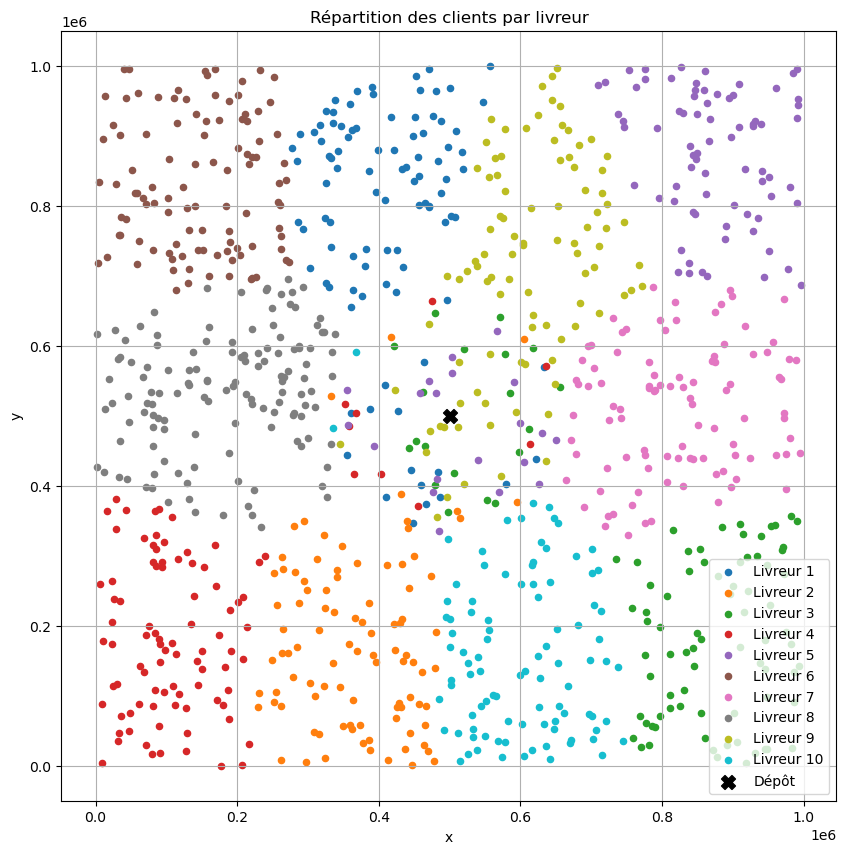

C:\Users\ER\AppData\Local\Temp\ipykernel_19448\1757691803.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", len(tours))


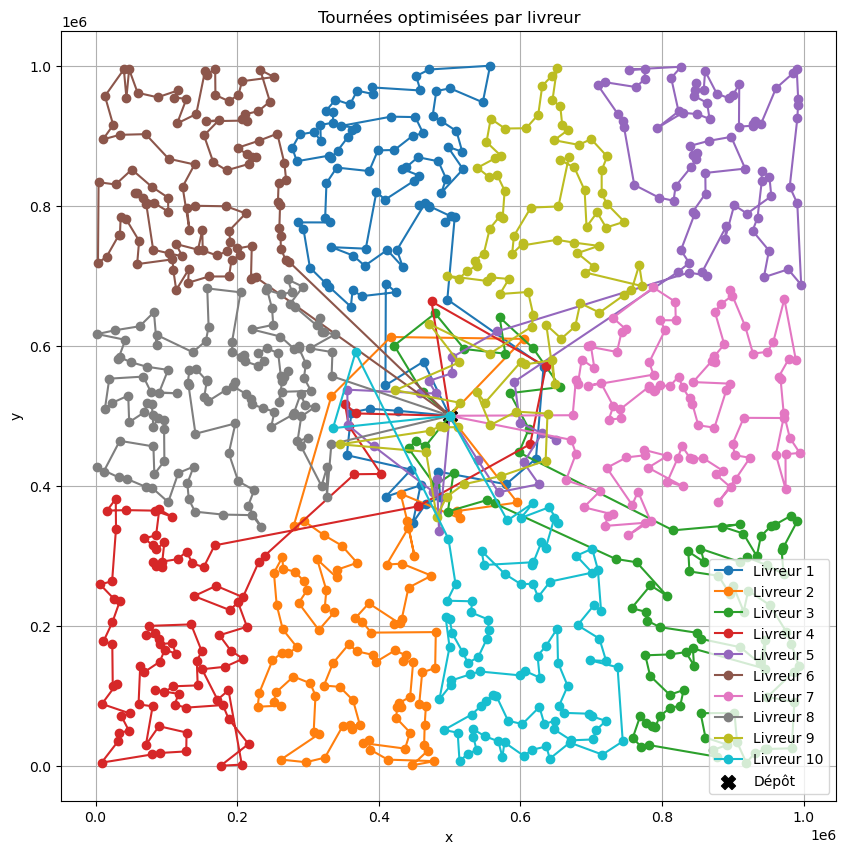

In [145]:
result = solve_real_problem_with_kmeans_and_central_balancing()
plot_clusters(result["positions"], result["clusters"])
plot_optimized_tours(result["positions"], result["tours"])


C:\Users\ER\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


Livreur 1: 99 clients, distance = 4,212,460
Livreur 2: 99 clients, distance = 4,156,126
Livreur 3: 98 clients, distance = 4,479,272
Livreur 4: 98 clients, distance = 4,695,585
Livreur 5: 110 clients, distance = 4,413,608
Livreur 6: 98 clients, distance = 4,813,029
Livreur 7: 98 clients, distance = 4,263,752
Livreur 8: 98 clients, distance = 4,548,140
Livreur 9: 104 clients, distance = 4,399,306
Livreur 10: 98 clients, distance = 4,132,283

Distance maximale (livreur le plus chargé): 4,813,029
Distances moyennes par livreur: 4,411,356.10
Nombre moyen de clients par livreur: 100.00


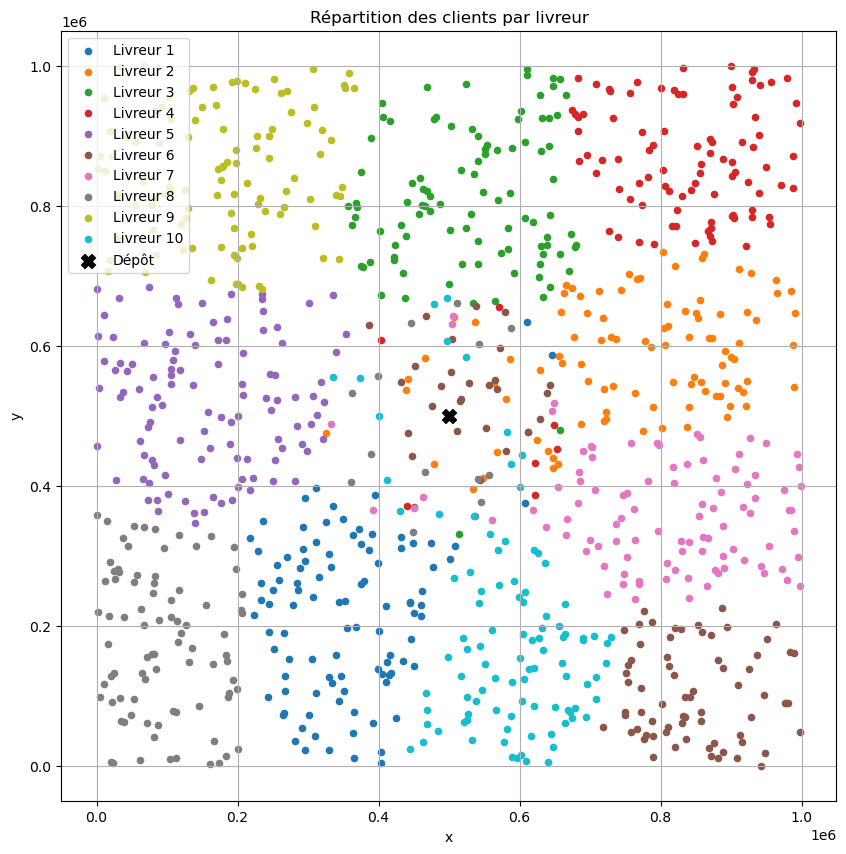

C:\Users\ER\AppData\Local\Temp\ipykernel_19448\1757691803.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", len(tours))


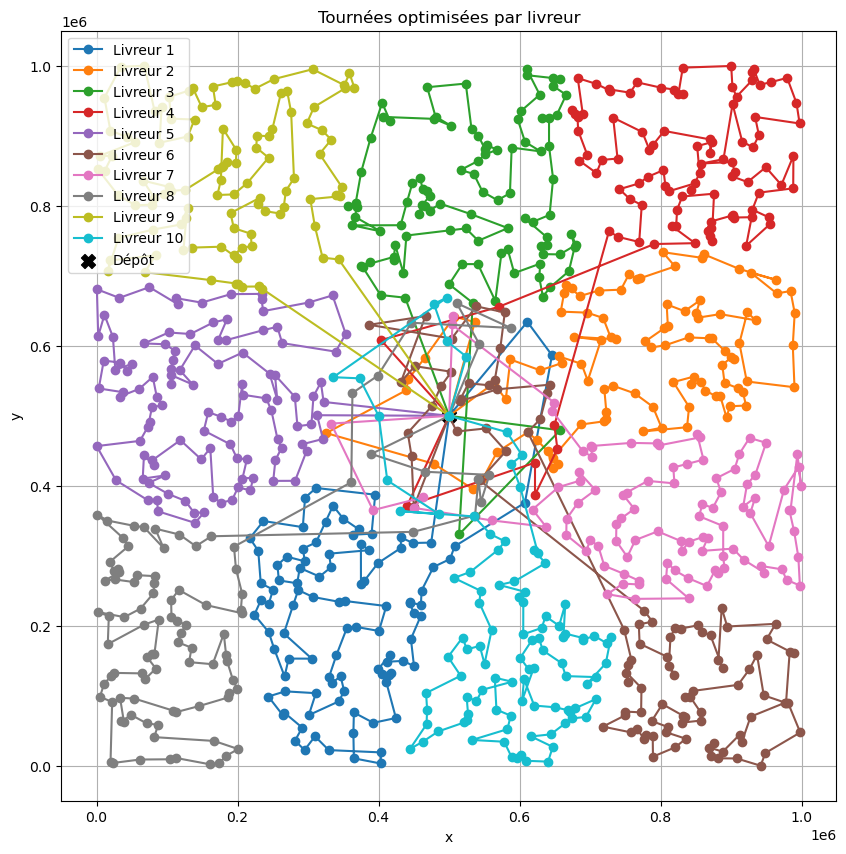

In [176]:
result = solve_real_problem_with_kmeans_and_central_balancing(alpha=.6)
plot_clusters(result["positions"], result["clusters"])
plot_optimized_tours(result["positions"], result["tours"])

# Rapport d'expérience : Résolution du problème réel

## Objectif

Le but de cette expérience est d'adapter les algorithmes de résolution du problème du voyageur de commerce (TSP) à un cas réel, où :

- Le nombre de clients est d’environ **1000**.
- Il y a environ **10 livreurs** pouvant opérer en parallèle.
- L'objectif est de minimiser le **temps total de distribution**, i.e., minimiser le temps pris par le livreur le plus lent.

---

## Approche choisie : Recherche locale

Après comparaison des algorithmes exacts (DP, MILP) et heuristiques (Christofides, recherche locale), l'approche basée sur la **recherche locale** a été retenue pour le problème réel.

### Raisons du choix :
- **DP** et **MILP** sont inadaptés pour des tailles **> 30-40** clients en raison de leur complexité exponentielle.
- **Christofides**, bien que rapide, montre une **qualité de solution très variable**.
- **Recherche locale** offre un **compromis** acceptable entre temps de calcul et qualité des solutions, même pour des instances de taille **500-1000**.

---

## Méthodologie

1. Génération aléatoire de **1000 clients** sur une grille de taille **n² × n²**, avec le dépôt placé au centre.
2. Clustering en deux étapes :
   - Application de **KMeans** sur une partie des clients éloignés du dépôt.
   - Répartition **équitable des clients proches du dépôt** entre les livreurs les **moins chargés**, en tenant compte à la fois du **nombre de clients** et de la **distance déjà affectée**.
3. Pour chaque cluster :
   - Optimisation de la tournée avec **recherche locale**.
   - Mesure de la distance totale parcourue par chaque livreur.

---

## Résultats obtenus

### Variante avec **alpha = 0.5**

- Temps maximal pris par un livreur : **4,871,165**
- Moyenne des distances de tournée : **4,377,243**
- Nombre moyen de clients : **100.00**

**Répartition typique :**

```
Livreur 1: 96 clients, distance = 4,460,074
Livreur 2: 96 clients, distance = 4,408,873
Livreur 3: 95 clients, distance = 4,758,239
Livreur 4: 95 clients, distance = 4,767,970
Livreur 5: 95 clients, distance = 4,871,165
Livreur 6: 103 clients, distance = 4,242,974
Livreur 7: 99 clients, distance = 4,001,923
Livreur 8: 131 clients, distance = 4,473,893
Livreur 9: 95 clients, distance = 4,262,307
Livreur 10: 95 clients, distance = 4,170,061
```

---

### Variante avec **alpha = 0.6**

- Temps maximal pris par un livreur : **4,813,029**
- Moyenne des distances de tournée : **4,350,346**
- Nombre moyen de clients : **100.00**

**Répartition typique :**

```
Livreur 1: 99 clients, distance = 4,212,460
Livreur 2: 99 clients, distance = 4,156,126
Livreur 3: 98 clients, distance = 4,479,272
Livreur 4: 98 clients, distance = 4,695,585
Livreur 5: 110 clients, distance = 4,413,608
Livreur 6: 98 clients, distance = 4,813,029
Livreur 7: 98 clients, distance = 4,263,752
Livreur 8: 98 clients, distance = 4,548,140
Livreur 9: 104 clients, distance = 4,399,306
Livreur 10: 98 clients, distance = 4,132,283
```

---

## Conclusion

L’approche hybride combinant **KMeans** sur les clients éloignés et une **distribution pondérée des clients centraux** a permis d’atteindre un excellent équilibre à la fois :

- en nombre de clients par livreur,
- en distance totale de chaque tournée.

Le paramètre `alpha` permet d’ajuster l’importance relative du **nombre de clients** par rapport à la **distance totale**, avec de très bons résultats obtenus entre `alpha = 0.5` et `0.6`.

Cette méthode surpasse nettement les versions naïves ou non équilibrées, tant sur le plan visuel que numérique. Elle constitue une solution efficace et adaptable pour des cas réels à grande échelle.
